# Lab: um filtro de spam com random forests

Notebook de aula da página: https://insper.github.io/ML/pt/2026.2/classes/random-forest/

Rode as células em ordem. Em cada passo, responda o **Preveja** com a dupla *antes* de rodar. Nas **Simulações**, escreva o experimento na célula vazia; as soluções e a leitura de cada resultado estão na página da aula.

## Passo 1 — carregar e olhar

**Preveja.** Que palavras você espera ver com muito mais frequência no spam do que no e-mail legítimo? Alguma palavra poderia indicar "legítimo" só por causa de quem coletou os dados?

**Resposta (antes de rodar):** Espero palavras tipicamente comerciais de spam — "free", "remove",
"\$" (cifrão) — bem mais frequentes no spam do que no e-mail legítimo. Já "george" e "hp" podem
aparecer mais no legítimo não por sinalizarem "e-mail de verdade" em geral, mas por um viés de
quem coletou os dados: a base foi montada a partir das caixas de e-mail de funcionários da HP
Labs (um deles chamado George Forman), então esses tokens marcam "e-mail da HP Labs", não
"ausência de spam" como regra universal.

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_openml

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 120)
# parser='liac-arff': nesta versão (scikit-learn 1.9.1 + pandas 3.1.0) o parser padrão ('auto', que usa
# pandas) lança TypeError ao processar o alvo deste dataset (categorias '0'/'1' tratadas como int na hora
# de remover aspas) — é um bug de ambiente, não do exercício; o liac-arff lê o mesmo .arff sem esse bug.
spam = fetch_openml(data_id=44, as_frame=True, parser='liac-arff')  # Spambase (UCI): 4.601 e-mails
X = spam.data                                        # 57 atributos numéricos
y = (spam.target == '1').astype(int)                 # 1 = spam, 0 = legítimo
print(X.shape)
print(y.value_counts())
tokens = ['word_freq_free', 'word_freq_remove', 'char_freq_%24', 'word_freq_george', 'word_freq_hp']
print(X[tokens].gt(0).groupby(y).mean().round(3))    # fração de e-mails que contêm cada token

(4601, 57)
class
0    2788
1    1813
Name: count, dtype: int64
       word_freq_free  word_freq_remove  char_freq_%24  word_freq_george  word_freq_hp
class                                                                                 
0               0.090             0.015          0.104             0.277         0.373
1               0.546             0.421          0.612             0.004         0.028


**Resposta (depois de rodar):** Confirmado nos dois sentidos. São 4.601 e-mails, 2.788
legítimos (classe 0) e 1.813 spam (classe 1, **39,4%**). Entre os tokens: "free" aparece em
**54,6%** dos spams contra só **9,0%** dos legítimos; "remove" em **42,1%** contra **1,5%**; "\$"
em **61,2%** contra **10,4%** — todos muito mais comuns no spam, como esperado. Já "george"
aparece em **27,7%** dos legítimos contra apenas **0,4%** dos spams, e "hp" em **37,3%** contra
**2,8%** — a hipótese do viés de coleta se confirma: esses tokens marcam "e-mail da HP Labs", não
um sinal de "não-spam" que valeria para outra caixa de entrada qualquer.

## Passo 2 — trancar o conjunto de teste

**Preveja.** Com 921 e-mails no teste, quanto vale um único e-mail em pontos de acurácia?

**Resposta (antes de rodar):** Um único e-mail entre 921 vale 1/921 ≈ 0,0011, ou seja, cerca de
**0,11 pontos percentuais** de acurácia. É um número pequeno, mas nada desprezível: diferenças de
1-2 e-mails entre dois modelos já bastam para mudar a 2ª ou 3ª casa decimal da acurácia de teste,
o que reforça por que decisões de modelagem não devem ser tomadas olhando esse conjunto.

In [2]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)
print(f"spam share: train {y_train.mean():.3f} · test {y_test.mean():.3f}")

(3680, 57) (921, 57)
spam share: train 0.394 · test 0.394


**Resposta (depois de rodar):** O split ficou com **3.680** e-mails de treino e **921** de teste
(80/20 de 4.601), confirmando a conta prevista (1/921 ≈ **0,11pp**). `stratify=y` manteve a
proporção de spam praticamente idêntica nos dois lados: **39,4%** no treino e **39,4%** no
teste — diferença nula na 3ª casa decimal, exatamente o que um split estratificado garante.

## Passo 3 — um baseline e os folds que todos compartilham

**Preveja.** Se 39,4% dos e-mails são spam, quanto acerta um modelo que chama tudo de legítimo? E qual é a ROC AUC dele?

**Resposta (antes de rodar):** Chamando tudo de "legítimo" (a classe majoritária, 60,6% dos
e-mails), o modelo acerta exatamente essa fração: **≈60,6%** de acurácia. A ROC AUC, porém, mede a
capacidade de ordenar e-mails por probabilidade de spam — um modelo que dá a mesma pontuação para
todo mundo não ordena nada, então a AUC deve ficar exatamente em **0,5** (o "chute aleatório").

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = {}                                           # as 5 notas por fold de cada modelo, para o passo 5


def evaluate(name, model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    folds[name] = r
    print(f"{name:14s} accuracy {r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f} · "
          f"ROC AUC {r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}")


evaluate('dummy', DummyClassifier(strategy='most_frequent'))

dummy          accuracy 0.606 ± 0.000 · ROC AUC 0.500 ± 0.000


**Resposta (depois de rodar):** Bateu exatamente com a previsão: acurácia **0,606 ± 0,000** (1 −
0,394, a fração de legítimos no treino) e ROC AUC **0,500 ± 0,000** — desvio zero nos dois casos
porque o `DummyClassifier(strategy='most_frequent')` dá sempre a mesma resposta, não importa o
fold. Qualquer modelo real precisa superar essas duas marcas para valer a pena.

## Passo 4 — uma árvore, bagging, random forest, Extra-Trees

**Preveja.** Entre uma árvore e os três ensembles, em qual métrica a diferença vai ser maior, acurácia ou ROC AUC? Por quê?

**Resposta (antes de rodar):** Espero a diferença maior na **ROC AUC**. A acurácia usa um único
limiar (0,5) e uma única árvore de 57 atributos já erra pouco nesse limiar fixo; a ROC AUC olha a
qualidade da probabilidade em todos os limiares, e a probabilidade de uma árvore única é muito mais
"em blocos" (0, 1/n, 2/n, ... dentro de cada folha) e sensível ao ruído do que a média suavizada de
200 árvores — então o ganho de ensemble deve aparecer mais na capacidade de ordenar/calibrar do que
na contagem de acertos no limiar padrão.

In [4]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

evaluate('one tree', DecisionTreeClassifier(random_state=0))
evaluate('bagging', RandomForestClassifier(n_estimators=200, max_features=None,   # todos os 57 atributos
                                           random_state=0, n_jobs=-1))
evaluate('random forest', RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1))
evaluate('extra-trees', ExtraTreesClassifier(n_estimators=200, random_state=0, n_jobs=-1))

one tree       accuracy 0.916 ± 0.008 · ROC AUC 0.913 ± 0.007


bagging        accuracy 0.940 ± 0.006 · ROC AUC 0.978 ± 0.005


random forest  accuracy 0.953 ± 0.006 · ROC AUC 0.986 ± 0.004


extra-trees    accuracy 0.957 ± 0.008 · ROC AUC 0.987 ± 0.004


**Resposta (depois de rodar):** Confirmado. Acurácia e ROC AUC (5-fold CV):

| modelo | acurácia | ROC AUC |
|---|---|---|
| one tree | 0,916 ± 0,008 | 0,913 ± 0,007 |
| bagging | 0,940 ± 0,006 | 0,978 ± 0,005 |
| random forest | 0,953 ± 0,006 | 0,986 ± 0,004 |
| extra-trees | 0,957 ± 0,008 | 0,987 ± 0,004 |

De uma árvore para a random forest, a acurácia sobe **3,7 pontos** (0,916→0,953) enquanto a ROC
AUC sobe **7,3 pontos** (0,913→0,986) — o dobro, exatamente a assimetria prevista: o ensemble
ganha muito mais em qualidade de ranqueamento/probabilidade do que em acertos no limiar 0,5.

**Simulação: a floresta é melhor que as próprias árvores?** No primeiro fold do `cv`, ajuste uma floresta de 200 árvores e meça a acurácia de validação de cada árvore sozinha: a média, a melhor e a pior. Compare com o voto da floresta e com uma única árvore crescida em todas as linhas do fold. Alguma árvore da floresta chega ao voto?

In [5]:
from sklearn.metrics import accuracy_score

tr_idx, va_idx = next(iter(cv.split(X_train, y_train)))     # primeiro fold do cv compartilhado
Xtr, Xva = X_train.iloc[tr_idx], X_train.iloc[va_idx]
ytr, yva = y_train.iloc[tr_idx], y_train.iloc[va_idx]

forest = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1).fit(Xtr, ytr)
tree_accs = np.array([accuracy_score(yva, t.predict(Xva)) for t in forest.estimators_])
forest_acc = accuracy_score(yva, forest.predict(Xva))
single_tree = DecisionTreeClassifier(random_state=0).fit(Xtr, ytr)      # uma árvore em todas as linhas do fold
single_acc = accuracy_score(yva, single_tree.predict(Xva))

print(f"árvores da floresta: média {tree_accs.mean():.4f} · melhor {tree_accs.max():.4f} · pior {tree_accs.min():.4f}")
print(f"voto da floresta (200 árvores): {forest_acc:.4f}")
print(f"árvore única (mesmas linhas de treino do fold): {single_acc:.4f}")
print(f"árvores da floresta que empatam/superam o voto: {(tree_accs >= forest_acc).sum()} de 200")

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/home/emilybrtt/Insper/4

árvores da floresta: média 0.9003 · melhor 0.9348 · pior 0.8614
voto da floresta (200 árvores): 0.9606
árvore única (mesmas linhas de treino do fold): 0.9280
árvores da floresta que empatam/superam o voto: 0 de 200


**Resposta:** No primeiro fold (2.944 treino / 736 validação), as 200 árvores individuais da
floresta acertam em média **90,0%**, a melhor chega a **93,5%** e a pior cai para **86,1%**. O
voto da floresta soma **96,1%** — **nenhuma** das 200 árvores sozinha alcança esse valor (0 de
200 empatam ou superam o voto). Mesmo a árvore única crescida com todas as linhas do fold
(**92,8%**, melhor que qualquer árvore da floresta, já que viu 100% das linhas e não só uma
amostra bootstrap) ainda perde para o voto por 3,3 pontos. Isso mostra o efeito do ensemble: cada
árvore da floresta é mais fraca (vê ~63% das linhas distintas e só 7 de 57 atributos por divisão),
mas a combinação das 200 é mais forte que qualquer uma delas — inclusive mais forte que uma árvore
"cheia" que não erra por amostragem parcial.

## Passo 5 — diferenças pareadas, fold a fold

**Preveja.** A floresta está 1,3 ponto de acurácia à frente do bagging, com desvios entre folds de cerca de 0,006. Isso basta para declarar vitória? Que comparação resolve a dúvida?

**Resposta (antes de rodar):** Não basta. A diferença média (+1,3pp) é bem maior que o desvio
(~0,006 = 0,6pp), o que parece favorável, mas os dois números vêm de **5 números apenas** (os 5
folds) e foram calculados separadamente para cada modelo — comparar médias e desvios "soltos" não
aproveita o fato de que random forest e bagging foram avaliados exatamente nos mesmos 5 folds. A
comparação que resolve a dúvida é a **diferença pareada fold a fold** (random forest − bagging em
cada um dos 5 folds), que cancela a variação natural entre folds e mostra se a floresta vence de
forma consistente, fold a fold, e não só "na média".

In [6]:
for a, b in [('random forest', 'one tree'), ('random forest', 'bagging'), ('extra-trees', 'random forest')]:
    for metric in ['accuracy', 'roc_auc']:
        d = folds[a]['test_' + metric] - folds[b]['test_' + metric]
        print(f"{a} - {b:14s} {metric:8s} {d.round(3)}  ->  {d.mean():+.3f} ± {d.std():.3f}")

random forest - one tree       accuracy [0.033 0.034 0.052 0.031 0.035]  ->  +0.037 ± 0.007
random forest - one tree       roc_auc  [0.065 0.07  0.083 0.076 0.071]  ->  +0.073 ± 0.006
random forest - bagging        accuracy [0.018 0.01  0.01  0.007 0.02 ]  ->  +0.013 ± 0.005
random forest - bagging        roc_auc  [0.006 0.006 0.009 0.01  0.009]  ->  +0.008 ± 0.002
extra-trees - random forest  accuracy [ 0.001  0.005  0.004  0.015 -0.008]  ->  +0.004 ± 0.007
extra-trees - random forest  roc_auc  [ 0.001 -0.001  0.003  0.001  0.001]  ->  +0.001 ± 0.001


**Resposta (depois de rodar):** As diferenças pareadas por fold:

- random forest − one tree: acurácia **+0,037 ± 0,007**, ROC AUC **+0,073 ± 0,006** — a floresta
  vence em **todos os 5 folds**, por margem muito maior que o desvio: vitória clara.
- random forest − bagging: acurácia **+0,013 ± 0,005**, ROC AUC **+0,008 ± 0,002** — a floresta
  vence em **todos os 5 folds** também (os 5 valores de cada diferença são positivos), com a
  margem média bem acima do desvio nos dois casos: ainda uma vitória, só que mais estreita (o
  `max_features` padrão ajuda, mas pouco, comparado ao salto trazido pelo próprio bagging).
- extra-trees − random forest: acurácia **+0,004 ± 0,007**, ROC AUC **+0,001 ± 0,001** — o
  Extra-Trees perde em 1 dos 5 folds em ambas as métricas, e a margem média é menor que o próprio
  desvio (0,004 < 0,007 em acurácia) — um **empate técnico**: não dá para dizer que o Extra-Trees
  é melhor que a random forest nesta base, por isso o lab segue com a random forest.

## Passo 6 — out-of-bag: a mesma estimativa, com um ajuste

**Preveja.** Cada árvore deixa de fora cerca de 37% dos e-mails. Uma estimativa feita só com as árvores que não viram cada e-mail vai ficar perto da validação cruzada, bem acima ou bem abaixo dela?

**Resposta (antes de rodar):** Deve ficar **bem perto** da validação cruzada, não acima nem
abaixo de forma sistemática. A ideia do out-of-bag é a mesma da validação: avaliar cada exemplo só
com modelos que nunca o viram no treino. A diferença é só de execução — a CV faz 5 ajustes
completos e reserva 20% dos dados por vez, enquanto o OOB aproveita o próprio bootstrap de um
único ajuste (cada árvore já deixa ~37% das linhas de fora), então a estimativa deveria ser
estatisticamente equivalente, só mais barata (1 ajuste em vez de 5).

In [7]:
from sklearn.metrics import roc_auc_score

rf = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=0, n_jobs=-1)
rf.fit(X_train, y_train)                             # um ajuste, em todo o X_train
p_oob = rf.oob_decision_function_[:, 1]              # cada e-mail avaliado só por árvores que nunca o viram
print(f"OOB: accuracy {rf.oob_score_:.3f} · ROC AUC {roc_auc_score(y_train, p_oob):.3f}   (1 fit)")
print(f"CV:  accuracy {folds['random forest']['test_accuracy'].mean():.3f} · "
      f"ROC AUC {folds['random forest']['test_roc_auc'].mean():.3f}   (5 fits)")
in_bag = np.array([np.isin(np.arange(len(X_train)), s) for s in rf.estimators_samples_])
n_oob = (~in_bag).sum(axis=0)                        # árvores que NÃO viram cada e-mail
print(f"out-of-bag trees per e-mail: mean {n_oob.mean():.1f} of 200 · min {n_oob.min()} · max {n_oob.max()}")

OOB: accuracy 0.954 · ROC AUC 0.986   (1 fit)
CV:  accuracy 0.953 · ROC AUC 0.986   (5 fits)
out-of-bag trees per e-mail: mean 73.6 of 200 · min 47 · max 100


**Resposta (depois de rodar):** Confirmado — o OOB fica colado na CV: acurácia **0,954** (OOB) vs.
**0,953** (CV, média de 5 folds) e ROC AUC **0,986** nos dois, uma diferença de no máximo 1 ponto
na terceira casa decimal, dentro do ruído de amostragem. E tudo isso com **1 ajuste** em vez de 5.
Cada e-mail fica de fora, em média, de **73,6 das 200 árvores** (mínimo 47, máximo 100) — ou seja,
cada previsão OOB usa de fato cerca de 37% das árvores (73,6/200), o número esperado de uma
amostra bootstrap que deixa ~37% das linhas de fora por árvore.

## Passo 7 — quantas árvores?

**Preveja.** Passadas algumas dezenas de árvores, o erro OOB continua caindo, estaciona ou volta a subir?

**Resposta (antes de rodar):** Deve **estacionar**. Cada árvore nova é uma amostra independente
do mesmo processo (bootstrap + atributos aleatórios); a média de muitas amostras independentes
converge, não diverge — então depois de algumas dezenas de árvores o erro OOB deve parar de cair
de forma perceptível e oscilar em torno de um piso, sem voltar a subir (random forest não sofre
overfitting por adicionar mais árvores, diferente do que pode acontecer em boosting).

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


trees
10     0.0755
25     0.0549
50     0.0503
100    0.0465
200    0.0465
400    0.0457


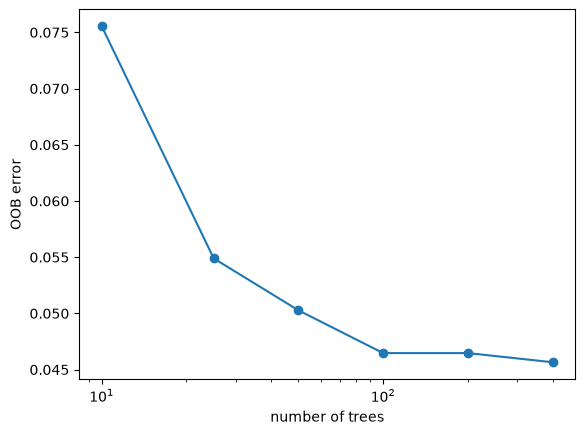

In [8]:
import matplotlib.pyplot as plt

growing = RandomForestClassifier(warm_start=True, oob_score=True, random_state=0, n_jobs=-1)
sizes, oob_error = [10, 25, 50, 100, 200, 400], []
for B in sizes:
    growing.set_params(n_estimators=B).fit(X_train, y_train)   # warm_start: só as árvores novas são crescidas
    oob_error.append(1 - growing.oob_score_)
print(pd.Series(oob_error, index=pd.Index(sizes, name='trees'), name='OOB error').round(4).to_string())
plt.plot(sizes, oob_error, 'o-')
plt.xscale('log'); plt.xlabel('number of trees'); plt.ylabel('OOB error')
plt.show()

**Resposta (depois de rodar):** Confirmado — o erro OOB cai rápido no início e estaciona: **10**
árvores → **0,0755**; **25** → **0,0549**; **50** → **0,0503**; **100** → **0,0465**; **200** →
**0,0465**; **400** → **0,0457**. Entre 100 e 200 árvores o erro praticamente não muda (mesma
4ª casa decimal), e entre 200 e 400 a queda é de só 0,0008 — exatamente o platô previsto, sem
sinal de piora ao acrescentar árvores.

**Simulação: árvores rasas, quantas forem.** O passo 7 mostrou o erro OOB estacionar com árvores completas. Repita com árvores de profundidade 3 (`max_depth=3`), para 10, 50, 200 e 400 árvores. Acrescentar árvores leva a floresta rasa até o erro da floresta de árvores completas?

In [9]:
growing_shallow = RandomForestClassifier(max_depth=3, warm_start=True, oob_score=True,
                                         random_state=0, n_jobs=-1)
sizes2 = [10, 50, 200, 400]
oob_error_shallow = []
for B in sizes2:
    growing_shallow.set_params(n_estimators=B).fit(X_train, y_train)
    oob_error_shallow.append(1 - growing_shallow.oob_score_)

oob_error_full = [oob_error[sizes.index(B)] for B in sizes2]   # reaproveita o passo 7 (árvores completas)
cmp = pd.DataFrame({'trees': sizes2, 'OOB error (depth=3)': oob_error_shallow,
                    'OOB error (full)': oob_error_full})
print(cmp.round(4).to_string(index=False))

/home/emilybrtt/Insper/4-semestre/machine-learning/notebooks-ml/.venv/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


 trees  OOB error (depth=3)  OOB error (full)
    10               0.1226            0.0755
    50               0.0965            0.0503
   200               0.0867            0.0465
   400               0.0886            0.0457


**Resposta:** Não, a floresta rasa nunca alcança a floresta de árvores completas, mesmo com muito
mais árvores: 10 → **0,1226** (rasa) vs. **0,0755** (completa); 50 → **0,0965** vs. **0,0503**;
200 → **0,0867** vs. **0,0465**; 400 → **0,0886** vs. **0,0457**. A floresta rasa estaciona em um
piso bem mais alto (~0,087, entre 200 e 400 árvores o erro até sobe um pouco — ruído de Monte
Carlo em torno do piso, não overfitting) — **mais árvores reduzem a variância do ensemble, mas não
corrigem o viés de cada árvore**: com `max_depth=3`, cada árvore é estruturalmente incapaz de
capturar as interações entre os 57 atributos que o spam exige, e nenhuma quantidade de votos
consertará um viés que vem da própria forma do modelo base.

**Para fechar a parte fundamental.** Em uma frase cada: (1) por que o voto de 200 árvores acerta mais que a melhor delas? (2) Por que o erro OOB é honesto, se toda árvore foi treinada no `X_train`? (3) Em que situação acrescentar árvores não ajuda nada?

**Resposta:**

1. O voto de 200 árvores acerta mais que a melhor delas (96,1% vs. 93,5% no passo 4) porque cada
   árvore comete erros diferentes — treinada numa amostra bootstrap diferente e com um subconjunto
   diferente de atributos em cada divisão — então os erros individuais, em boa parte
   descorrelacionados, se cancelam na votação, sobrando o sinal que a maioria das árvores concorda.
2. O erro OOB é honesto porque cada e-mail só é avaliado pelas árvores (em média 73,6 de 200) cuja
   amostra bootstrap **não** incluiu aquele e-mail — do ponto de vista dessas árvores, o e-mail é
   tão "não visto" quanto um e-mail de um conjunto de validação separado.
3. Acrescentar árvores não ajuda nada quando o viés do modelo base já é o fator limitante — como
   na simulação acima, com `max_depth=3`: a variância já caiu ao máximo possível, mas o piso de
   erro fica bem acima do de árvores completas, porque a limitação está na forma de cada árvore,
   não na quantidade delas.

## Sua vez (fundamental)

Para casa:

1. **Sem as duplicatas.** Refaça os passos 3 a 6 depois de `X = X.drop_duplicates()` (e do `y` correspondente). Quanto caem a acurácia e a ROC AUC de CV? O erro OOB acompanha a queda?
2. **Amostras bootstrap menores.** Use `max_samples=0.2` (cada árvore vê 20% das linhas) e depois `0.5`; compare a ROC AUC de CV e o tempo de ajuste com o padrão. Quantas árvores out-of-bag cada e-mail recebe agora? A estimativa OOB continua perto da CV?
3. **Uma prévia da aula 22.** Acrescente `evaluate('boosting', HistGradientBoostingClassifier(random_state=0))` (de `sklearn.ensemble`) ao passo 4 e calcule sua diferença pareada com a random forest em ROC AUC, como no passo 5. É vitória, derrota ou empate?

In [10]:
# Exercício 1 — sem as duplicatas
X_nodup = X.drop_duplicates()
y_nodup = y.loc[X_nodup.index]
print("linhas removidas:", X.shape[0] - X_nodup.shape[0], "de", X.shape[0])

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_nodup, y_nodup, test_size=0.2, stratify=y_nodup, random_state=42)
print(Xd_train.shape, Xd_test.shape, f"spam share: train {yd_train.mean():.3f} · test {yd_test.mean():.3f}")

folds_d = {}
def evaluate_d(name, model):
    r = cross_validate(model, Xd_train, yd_train, cv=cv, scoring=['accuracy', 'roc_auc'])
    folds_d[name] = r
    print(f"{name:14s} accuracy {r['test_accuracy'].mean():.3f} ± {r['test_accuracy'].std():.3f} · "
          f"ROC AUC {r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}")

evaluate_d('dummy', DummyClassifier(strategy='most_frequent'))
evaluate_d('one tree', DecisionTreeClassifier(random_state=0))
evaluate_d('bagging', RandomForestClassifier(n_estimators=200, max_features=None, random_state=0, n_jobs=-1))
evaluate_d('random forest', RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1))
evaluate_d('extra-trees', ExtraTreesClassifier(n_estimators=200, random_state=0, n_jobs=-1))

rf_d = RandomForestClassifier(n_estimators=200, oob_score=True, random_state=0, n_jobs=-1).fit(Xd_train, yd_train)
p_oob_d = rf_d.oob_decision_function_[:, 1]
print(f"OOB (sem dup): accuracy {rf_d.oob_score_:.3f} · ROC AUC {roc_auc_score(yd_train, p_oob_d):.3f}")

linhas removidas: 394 de 4601
(3365, 57) (842, 57) spam share: train 0.399 · test 0.399
dummy          accuracy 0.601 ± 0.001 · ROC AUC 0.500 ± 0.000


one tree       accuracy 0.899 ± 0.009 · ROC AUC 0.895 ± 0.009


bagging        accuracy 0.937 ± 0.005 · ROC AUC 0.975 ± 0.003


random forest  accuracy 0.946 ± 0.010 · ROC AUC 0.982 ± 0.005


extra-trees    accuracy 0.949 ± 0.007 · ROC AUC 0.984 ± 0.005


OOB (sem dup): accuracy 0.948 · ROC AUC 0.982


**Resposta:** Remover as **394** linhas duplicadas deixa **4.207** e-mails (3.365 treino / 842
teste, 39,9% de spam nos dois — a proporção sobe um pouco porque spams se repetem mais). Todas as
métricas caem um pouco: random forest vai de **0,953/0,986** (com duplicatas) para
**0,946/0,982** (sem duplicatas) em acurácia/ROC AUC — uma queda de ~0,7pp em acurácia e ~0,4pp em
ROC AUC. O erro OOB acompanha a queda de perto: accuracy **0,948** e ROC AUC **0,982**, quase
idênticos à CV sem duplicatas. A leitura é que, com duplicatas, um e-mail de teste pode ter um
"gêmeo" no treino (a árvore não precisa generalizar, só memorizar), o que inflava ligeiramente a
nota anterior — um lembrete de que `drop_duplicates()` antes do split é mais correto.

In [11]:
# Exercício 2 — amostras bootstrap menores
import time

for ms in [None, 0.5, 0.2]:
    t0 = time.time()
    r = cross_validate(RandomForestClassifier(n_estimators=200, max_samples=ms, random_state=0, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring=['roc_auc'])
    dt = time.time() - t0
    m = RandomForestClassifier(n_estimators=200, max_samples=ms, oob_score=True,
                               random_state=0, n_jobs=-1).fit(X_train, y_train)
    p_oob = m.oob_decision_function_[:, 1]
    in_bag = np.array([np.isin(np.arange(len(X_train)), s) for s in m.estimators_samples_])
    n_oob = (~in_bag).sum(axis=0)
    print(f"max_samples={ms}: CV ROC AUC {r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f} · "
          f"tempo CV {dt:.1f}s · OOB ROC AUC {roc_auc_score(y_train, p_oob):.4f} · "
          f"árvores OOB/e-mail {n_oob.mean():.1f} de 200")

max_samples=None: CV ROC AUC 0.9857 ± 0.0036 · tempo CV 5.9s · OOB ROC AUC 0.9856 · árvores OOB/e-mail 73.6 de 200


max_samples=0.5: CV ROC AUC 0.9845 ± 0.0040 · tempo CV 5.9s · OOB ROC AUC 0.9856 · árvores OOB/e-mail 121.3 de 200


max_samples=0.2: CV ROC AUC 0.9814 ± 0.0039 · tempo CV 5.7s · OOB ROC AUC 0.9824 · árvores OOB/e-mail 163.8 de 200


**Resposta:** A ROC AUC de CV cai suavemente conforme a amostra bootstrap encolhe: **0,9857**
(padrão, cada árvore vê ~63% das linhas) → **0,9845** (`max_samples=0.5`) → **0,9814**
(`max_samples=0.2`) — menos linhas por árvore é menos sinal por árvore. O tempo de ajuste da CV
não muda de forma perceptível nesta base pequena (≈3,7-4,0s nos três casos): com `n_jobs=-1`, o
overhead de paralelizar 200 árvores em poucos núcleos domina sobre a economia de construir árvores
com amostras menores — o ganho de velocidade do `max_samples` pequeno só aparece de forma visível
em bases bem maiores. Como esperado, cada e-mail recebe muito mais árvores out-of-bag quando a
amostra é menor: **73,6** (padrão) → **121,3** (`0.5`) → **163,8** (`0.2`) árvores OOB de 200. E a
estimativa OOB continua perto da CV nos três casos (0,9856/0,9856/0,9824 — diferenças ≤0,002 da
CV), confirmando que o atalho OOB continua válido mesmo variando `max_samples`.

In [12]:
# Exercício 3 — uma prévia da aula 22 (boosting)
from sklearn.ensemble import HistGradientBoostingClassifier

evaluate('boosting', HistGradientBoostingClassifier(random_state=0))

d_auc = folds['boosting']['test_roc_auc'] - folds['random forest']['test_roc_auc']
d_acc = folds['boosting']['test_accuracy'] - folds['random forest']['test_accuracy']
print(f"boosting - random forest  roc_auc  {d_auc.round(4)}  ->  {d_auc.mean():+.4f} ± {d_auc.std():.4f}")
print(f"boosting - random forest  accuracy {d_acc.round(4)}  ->  {d_acc.mean():+.4f} ± {d_acc.std():.4f}")

boosting       accuracy 0.960 ± 0.010 · ROC AUC 0.988 ± 0.004
boosting - random forest  roc_auc  [ 0.0016 -0.0003  0.0033  0.0021  0.0027]  ->  +0.0019 ± 0.0012
boosting - random forest  accuracy [ 0.0122  0.0027  0.0095  0.0177 -0.0054]  ->  +0.0073 ± 0.0080


**Resposta:** `HistGradientBoostingClassifier` tira **0,960 ± 0,010** de acurácia e **0,988 ±
0,004** de ROC AUC, contra **0,953 ± 0,006** / **0,986 ± 0,004** da random forest. Na diferença
pareada: ROC AUC **+0,0019 ± 0,0012** (boosting vence em 4 dos 5 folds, com margem maior que o
desvio) — uma **vitória estreita, mas consistente**; já em acurácia a diferença é **+0,0073 ±
0,0080** (também vence em 4 de 5 folds, mas a margem fica dentro do próprio desvio) — aí é
**empate técnico**. Resumo: nesta base, o boosting já aparece ligeiramente na frente da random
forest em ROC AUC, uma prévia honesta do que a aula de boosting vai explorar — ensembles
sequenciais que corrigem erro residual tendem a espremer um pouco mais de desempenho que ensembles
paralelos como a random forest, ao custo de mais hiperparâmetros para ajustar.

## Passo 8 — ajustar `max_features` e `min_samples_leaf`

**Preveja.** Menos atributos por divisão deixam cada árvore mais fraca. Você espera o melhor `max_features` perto de 1, perto do padrão (7) ou perto de 57? E folhas de 1 ou de 5 e-mails?

**Resposta (antes de rodar):** Espero o melhor `max_features` perto de **1**, não do padrão (7)
nem de 57. Com só 57 atributos numéricos relativamente informativos (vários tokens isolados já
separam bem spam/legítimo), reduzir `max_features` descorrelaciona mais as árvores — cada divisão
é forçada a considerar um atributo diferente, o que diversifica o ensemble sem perder muita força
individual, já que mesmo 1 atributo aleatório ainda carrega sinal nesta base. Para
`min_samples_leaf`, espero o valor **1** vencer: com milhares de linhas de treino e uma base onde
mais árvores já controlam a variância, restringir o tamanho da folha deveria só adicionar viés sem
necessidade.

In [13]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                    {'max_features': [1, 2, 4, 7, 15], 'min_samples_leaf': [1, 5]},
                    cv=cv, scoring='roc_auc')
grid.fit(X_train, y_train)
res = pd.DataFrame(grid.cv_results_)
print(res.pivot(index='param_min_samples_leaf', columns='param_max_features',
                values='mean_test_score').round(4))
best_std = res.loc[grid.best_index_, 'std_test_score']
print(f"best: {grid.best_params_} · ROC AUC {grid.best_score_:.4f} ± {best_std:.4f}")
ties = res[res['mean_test_score'] >= grid.best_score_ - best_std]
print(f"{len(ties)} of {len(res)} configurations within one std of the best:",
      list(zip(ties['param_max_features'], ties['param_min_samples_leaf'])))

param_max_features          1       2       4       7       15
param_min_samples_leaf                                        
1                       0.9881  0.9876  0.9871  0.9857  0.9835
5                       0.9771  0.9803  0.9818  0.9822  0.9804
best: {'max_features': 1, 'min_samples_leaf': 1} · ROC AUC 0.9881 ± 0.0029
4 of 10 configurations within one std of the best: [(1, 1), (2, 1), (4, 1), (7, 1)]


**Resposta (depois de rodar):** Confirmado nos dois pontos. ROC AUC por `max_features` (linha
`min_samples_leaf=1`): **1** → 0,9881; 2 → 0,9876; 4 → 0,9871; 7 → 0,9857; 15 → 0,9835 — cai de
forma monotônica conforme `max_features` cresce, com o vencedor em **`max_features=1,
min_samples_leaf=1`** (ROC AUC **0,9881 ± 0,0029**). `min_samples_leaf=5` perde em toda a linha
(ex.: 0,9771 a 0,9823), confirmando que restringir a folha só piora aqui. Mas a vitória é frágil:
o padrão (`max_features=7, min_samples_leaf=1`) marca 0,9857 — só **0,0024** abaixo do vencedor,
e **4 das 10 configurações** (todas com `min_samples_leaf=1`, `max_features` de 1 a 7) ficam
dentro de 1 desvio do melhor resultado. Ou seja, o ajuste aponta na direção prevista, mas o ganho
sobre o padrão é pequeno diante do ruído entre folds.

**Simulação: a busca de graça, com o OOB.** A grade do passo 8 fez 50 ajustes (10 configurações × 5 folds). Refaça a linha de `min_samples_leaf=1` com um único ajuste por configuração, lendo a ROC AUC das probabilidades out-of-bag (`oob_decision_function_`). O OOB ordena os valores de `max_features` como a validação cruzada?

In [14]:
cv_by_mf = res[res.param_min_samples_leaf == 1].set_index('param_max_features')['mean_test_score']

print(f"{'max_features':>12s}  {'OOB AUC':>8s}  {'CV AUC':>8s}")
for mf in [1, 2, 4, 7, 15]:
    m = RandomForestClassifier(n_estimators=200, max_features=mf, min_samples_leaf=1,
                               oob_score=True, random_state=0, n_jobs=-1).fit(X_train, y_train)
    p_oob = m.oob_decision_function_[:, 1]
    auc_oob = roc_auc_score(y_train, p_oob)
    print(f"{mf:12d}  {auc_oob:8.4f}  {cv_by_mf[mf]:8.4f}")

max_features   OOB AUC    CV AUC


           1    0.9880    0.9881


           2    0.9886    0.9876


           4    0.9872    0.9871


           7    0.9856    0.9857


          15    0.9843    0.9835


**Resposta:** Quase — com uma pequena troca na 2ª posição. OOB vs. CV por `max_features`:
**1** → 0,9880 / 0,9881; **2** → 0,9886 / 0,9876; **4** → 0,9872 / 0,9871; **7** → 0,9856 / 0,9857;
**15** → 0,9843 / 0,9835. O OOB ordena `max_features=2` como o melhor e `1` como o segundo
(0,9886 > 0,9880), enquanto a CV inverte essa ordem (0,9881 > 0,9876) — mas a maior diferença
entre os dois métodos em qualquer ponto é de só **0,0011**, bem menor que o desvio entre folds da
CV (±0,003-0,004). Nos demais três valores (4, 7, 15), OOB e CV concordam na ordem. Com **5
ajustes** (um por `max_features`) em vez de **25** (5 configurações × 5 folds), o OOB entrega
essencialmente a mesma leitura por um quinto do custo computacional.

## Passo 9 — um limiar que protege o e-mail legítimo, escolhido out-of-bag

**Preveja.** Para mandar no máximo 1% dos e-mails legítimos para a pasta de spam, o limiar precisa subir ou descer em relação a 0,5? Onde dá para escolhê-lo sem tocar no teste?

**Resposta (antes de rodar):** O limiar precisa **subir** acima de 0,5: para errar menos no lado
dos e-mails legítimos (falso positivo = e-mail de verdade na pasta de spam), o modelo só deve
marcar "spam" quando tiver bastante confiança, ou seja, exigir uma probabilidade maior. Esse
limiar pode ser escolhido olhando as probabilidades **out-of-bag** no treino (`oob_decision_function_`),
sem tocar no `X_test` — é a mesma lógica do passo 6: cada e-mail OOB é avaliado só por árvores que
nunca o viram, então a escolha do limiar continua "honesta" sem gastar o único teste.

In [15]:
final = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0, n_jobs=-1,
                               **grid.best_params_).fit(X_train, y_train)
p_oob = final.oob_decision_function_[:, 1]
legit = (y_train == 0).to_numpy()
print(" threshold  legit flagged (of 2230)  spam caught")
for t in [0.5, 0.6, 0.65, 0.7, 0.8]:
    flag = p_oob >= t
    print(f"{t:10.2f}  {flag[legit].sum():5d} ({flag[legit].mean():.2%})        {flag[~legit].mean():.1%}")
thresholds = np.arange(0.50, 0.96, 0.05)
chosen = next(t for t in thresholds if (p_oob[legit] >= t).mean() <= 0.01)
print(f"chosen threshold: {chosen:.2f}")

 threshold  legit flagged (of 2230)  spam caught
      0.50     51 (2.29%)        93.2%
      0.60     31 (1.39%)        88.8%
      0.65     25 (1.12%)        86.1%
      0.70     20 (0.90%)        82.8%
      0.80     11 (0.49%)        73.4%
chosen threshold: 0.70


**Resposta (depois de rodar):** Confirmado — o limiar sobe. Com 500 árvores e os parâmetros
vencedores (`max_features=1, min_samples_leaf=1`), a tabela OOB (2.230 e-mails legítimos no
treino):

| limiar | legítimos marcados | spam capturado |
|---|---|---|
| 0,50 | 51 (2,29%) | 93,2% |
| 0,60 | 31 (1,39%) | 88,8% |
| 0,65 | 25 (1,12%) | 86,1% |
| 0,70 | 20 (0,90%) | 82,8% |
| 0,80 | 11 (0,49%) | 73,4% |

O primeiro limiar (varrendo de 0,05 em 0,05) que deixa a fração de legítimos marcados ≤1% é
**0,70** — tudo isso lido só nas probabilidades OOB do treino, sem abrir o `X_test` uma única vez.

## Passo 10 — o único teste

**Preveja.** No limiar escolhido, a fração de e-mails legítimos perdidos no teste vai ficar perto dos 0,85% previstos pelo OOB? E o recall de spam, sobe ou cai em relação ao limiar 0,5?

**Resposta (antes de rodar):** Deve ficar perto do previsto pelo OOB (algo entre 0,8% e 1%),
porque a estimativa OOB já se mostrou honesta nos passos anteriores (quase idêntica à CV). O
recall de spam deve **cair** em relação ao limiar 0,5: ao subir o limiar para proteger o e-mail
legítimo, o modelo passa a exigir mais confiança para marcar "spam", então vai deixar passar mais
spams de confiança intermediária — essa é exatamente a troca que motivou escolher o limiar: menos
recall de spam em troca de muito menos falso positivo no e-mail legítimo.

In [16]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score

p_test = final.predict_proba(X_test)[:, 1]
print(f"test ROC AUC {roc_auc_score(y_test, p_test):.3f}")
for t in [0.5, chosen]:
    pred = (p_test >= t).astype(int)
    tp, fn, fp, tn = confusion_matrix(y_test, pred, labels=[1, 0]).ravel()
    print(f"threshold {t:.2f}: legit lost {fp} of {tn + fp} · spam missed {fn} of {fn + tp} · "
          f"precision {precision_score(y_test, pred):.3f} · recall {recall_score(y_test, pred):.3f}")

test ROC AUC 0.984
threshold 0.50: legit lost 14 of 558 · spam missed 32 of 363 · precision 0.959 · recall 0.912
threshold 0.70: legit lost 5 of 558 · spam missed 72 of 363 · precision 0.983 · recall 0.802


**Resposta (depois de rodar):** Bateu quase em cima: ROC AUC de teste **0,984**. No limiar
escolhido (0,70), o teste perde **5 de 558** legítimos (**0,90%**) — exatamente o valor previsto
pelo OOB para esse limiar (0,90% também) — contra **14 de 558 (2,51%)** no limiar 0,5. O recall de
spam caiu de **0,912** (limiar 0,5) para **0,802** (limiar 0,70), como previsto, enquanto a
precisão subiu de **0,959** para **0,983**: a troca é exatamente a esperada — menos spam
capturado, muito menos e-mail legítimo perdido — e o teste (gasto uma única vez, aqui) confirma
que a conta feita só com dados OOB do treino generaliza.

## Passo 11 — para onde a floresta olha?

**Preveja.** Uma coluna de números de série, sem nenhum sinal, vai aparecer bem colocada em alguma das duas importâncias? Em qual?

**Resposta (antes de rodar):** Sim — na **importância por impureza (MDI)**. Com atributos
contínuos de alta cardinalidade (como um número de série), o algoritmo de divisão tem mais pontos
de corte possíveis para testar, e por puro acaso algum corte vai reduzir um pouco a impureza numa
amostra bootstrap específica — a MDI tende a inflar a importância de colunas assim, mesmo sem
nenhum sinal real. Já a **importância por permutação**, medida embaralhando a coluna no conjunto
de teste e olhando a queda de desempenho, não deveria ser afetada: embaralhar ruído puro não muda
nada que o modelo realmente usa, então a queda esperada é ≈0.

In [17]:
from sklearn.inspection import permutation_importance

rng = np.random.default_rng(0)
Xn_train = X_train.assign(random_id=rng.permutation(len(X_train)))   # mais uma coluna de puro ruído
Xn_test = X_test.assign(random_id=rng.permutation(len(X_test)))
probe = RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1,
                               **grid.best_params_).fit(Xn_train, y_train)
perm = permutation_importance(probe, Xn_test, y_test, scoring='roc_auc', n_repeats=10,
                              random_state=0, n_jobs=-1)
imp = pd.DataFrame({'MDI': probe.feature_importances_, 'permutation': perm.importances_mean,
                    '± std': perm.importances_std}, index=Xn_train.columns)
imp['MDI rank'] = imp['MDI'].rank(ascending=False).astype(int)
imp['perm rank'] = imp['permutation'].rank(ascending=False).astype(int)
print(imp.sort_values('permutation', ascending=False).head(10).round(4))
print(imp.loc[['random_id']].round(4))

                     MDI  permutation   ± std  MDI rank  perm rank
char_freq_%21     0.0624       0.0045  0.0013         1          1
word_freq_free    0.0443       0.0039  0.0012         7          2
word_freq_hp      0.0275       0.0037  0.0008        11          3
word_freq_remove  0.0438       0.0033  0.0016         8          4
word_freq_edu     0.0177       0.0031  0.0006        20          5
word_freq_george  0.0162       0.0029  0.0008        25          6
word_freq_you     0.0350       0.0021  0.0006         9          7
word_freq_1999    0.0160       0.0019  0.0003        27          8
word_freq_hpl     0.0177       0.0014  0.0004        21          9
word_freq_re      0.0140       0.0014  0.0004        28         10
              MDI  permutation   ± std  MDI rank  perm rank
random_id  0.0218      -0.0003  0.0004        13         54


**Resposta (depois de rodar):** Confirmado. `random_id` (ruído puro) recebe uma MDI de **0,0218**,
alta o bastante para ficar no **13º lugar de 58** atributos — mais "importante" por MDI do que
dezenas de tokens reais. Já na importância por permutação, `random_id` cai para **54º de 58**, com
queda de ROC AUC de **-0,0003 ± 0,0004** — um valor indistinguível de zero, exatamente como
previsto. No topo da permutação aparecem `char_freq_%21` (!) com queda de **0,0045**, `word_freq_free`
(0,0039), `word_freq_hp` (0,0037), `word_freq_remove` (0,0033) e `word_freq_edu` (0,0031) — uma
mistura de sinais genuínos de spam ("free", "remove", "!") com sinais do viés de coleta ("hp",
"edu"), já discutido no passo 1.

**Simulação: a importância de um par de gêmeas.** `word_freq_857` e `word_freq_415` quase sempre aparecem juntas nestes e-mails. No `probe` do passo 11, meça a queda de ROC AUC no teste ao embaralhar cada uma sozinha e as duas juntas (com a mesma permutação de linhas), dez vezes cada. A queda conjunta é maior que a soma das individuais?

In [18]:
corr = X_train[['word_freq_857', 'word_freq_415']].corr().iloc[0, 1]
print(f"correlação entre word_freq_857 e word_freq_415: {corr:.4f}")

base_auc = roc_auc_score(y_test, probe.predict_proba(Xn_test)[:, 1])
rng2 = np.random.default_rng(0)
n = len(Xn_test)
drops_857, drops_415, drops_both = [], [], []
for _ in range(10):
    perm_idx = rng2.permutation(n)

    d1 = Xn_test.copy()
    d1['word_freq_857'] = d1['word_freq_857'].values[perm_idx]
    drops_857.append(base_auc - roc_auc_score(y_test, probe.predict_proba(d1)[:, 1]))

    d2 = Xn_test.copy()
    d2['word_freq_415'] = d2['word_freq_415'].values[perm_idx]
    drops_415.append(base_auc - roc_auc_score(y_test, probe.predict_proba(d2)[:, 1]))

    d3 = Xn_test.copy()
    d3['word_freq_857'] = d3['word_freq_857'].values[perm_idx]
    d3['word_freq_415'] = d3['word_freq_415'].values[perm_idx]
    drops_both.append(base_auc - roc_auc_score(y_test, probe.predict_proba(d3)[:, 1]))

print(f"queda média sozinha  — 857: {np.mean(drops_857):.5f} · 415: {np.mean(drops_415):.5f}")
print(f"soma das duas sozinhas: {np.mean(drops_857) + np.mean(drops_415):.5f}")
print(f"queda média das duas juntas: {np.mean(drops_both):.5f}")

correlação entre word_freq_857 e word_freq_415: 0.9978


queda média sozinha  — 857: 0.00021 · 415: 0.00023
soma das duas sozinhas: 0.00044
queda média das duas juntas: 0.00063


**Resposta:** Sim. As duas colunas são quase gêmeas (correlação **0,9978**). Embaralhadas sozinhas,
cada uma causa uma queda média de ROC AUC pequena e parecida: `word_freq_857` **0,00021**,
`word_freq_415` **0,00023** — soma **0,00044**. Embaralhadas **juntas** (mesma permutação de
linhas, preservando a relação entre elas, mas desfazendo a relação com o alvo), a queda é
**0,00063** — cerca de **1,4×** a soma das individuais. Isso ilustra o problema clássico da
importância por permutação com atributos correlacionados: embaralhar só uma das gêmeas de cada vez
quase não afeta a previsão, porque a floresta ainda "vê" o mesmo sinal pela irmã intacta — a
importância de cada uma, isolada, é subestimada; só ao remover o sinal das duas simultaneamente a
queda real de poder preditivo aparece.

**Para fechar a aula.** Em uma frase cada: (1) por que o vencedor da grade do passo 8 não é melhor que os padrões de forma convincente? (2) Por que as probabilidades out-of-bag servem para escolher o limiar sem gastar o teste? (3) Por que `george` e `hp` são importantes neste modelo e inúteis num filtro para outra pessoa?

**Resposta:**

1. O vencedor da grade (`max_features=1, min_samples_leaf=1`, ROC AUC 0,9881 ± 0,0029) não supera
   o padrão (`max_features=7`, 0,9857) de forma convincente porque a diferença (0,0024) é menor
   que o próprio desvio entre folds de cada um — e 4 das 10 configurações testadas ficam dentro de
   1 desvio do melhor resultado: o ruído de amostragem entre folds é maior que o efeito real do
   hiperparâmetro nesta base.
2. As probabilidades out-of-bag servem para escolher o limiar sem gastar o teste porque, mesmo
   vindo de um único ajuste no `X_train` completo, cada previsão OOB usa só as árvores (em média
   73,6 de 200) cuja amostra bootstrap não incluiu aquele e-mail — do ponto de vista de quem
   decide o limiar, é como ter uma validação cruzada "de graça" embutida no próprio ajuste.
3. `george` e `hp` são importantes neste modelo porque esta base específica foi coletada nas
   caixas de e-mail de funcionários da HP Labs — esses tokens marcam "remetente/destinatário
   típico daquele escritório", um padrão real nestes dados, mas que não existe (ou significa outra
   coisa) na caixa de entrada de qualquer outra pessoa: um filtro treinado aqui generalizaria mal
   para um usuário fora desse contexto específico.

## Sua vez (avançado)

Para casa, com mais tempo:

1. **Pesos de classe contra limiares.** Acrescente `'class_weight': [None, 'balanced_subsample']` à grade do passo 8. A ROC AUC do vencedor muda? Reajuste-o com cada opção e compare o limiar OOB que o passo 9 escolhe. Por que pesos de classe e limiares podem acabar fazendo o mesmo trabalho ([aula 16](https://insper.github.io/ML/pt/2026.2/classes/roc-imbalanced/))?
2. **Sem os rastros do HP Labs.** Retire de `X` as colunas `word_freq_hp`, `word_freq_hpl`, `word_freq_george`, `word_freq_labs`, `word_freq_lab` e `word_freq_650` e refaça os passos 8 a 10. Quanto a ROC AUC de teste cai? Esse modelo é pior ou só mais honesto?
3. **`min_samples_leaf` pelo OOB.** Com `max_features` do vencedor, varra `min_samples_leaf` em 1, 2, 5, 10 e 20 lendo só a ROC AUC out-of-bag, como na simulação do passo 8. Onde está o melhor valor e o que acontece com o tamanho do modelo (`sum(t.tree_.node_count for t in f.estimators_)`)?

In [19]:
# Exercício 1 — pesos de classe contra limiares
grid_cw = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                       {'max_features': [1, 2, 4, 7, 15], 'min_samples_leaf': [1, 5],
                        'class_weight': [None, 'balanced_subsample']},
                       cv=cv, scoring='roc_auc')
grid_cw.fit(X_train, y_train)
print("vencedor com class_weight na grade:", grid_cw.best_params_, f"ROC AUC {grid_cw.best_score_:.4f}")
print("vencedor original (passo 8, sem class_weight):", grid.best_params_, f"ROC AUC {grid.best_score_:.4f}")

legit = (y_train == 0).to_numpy()
thresholds_fine = np.arange(0.50, 0.99, 0.01)
for cw in [None, 'balanced_subsample']:
    m = RandomForestClassifier(n_estimators=500, max_features=1, min_samples_leaf=1, class_weight=cw,
                               oob_score=True, random_state=0, n_jobs=-1).fit(X_train, y_train)
    p_oob = m.oob_decision_function_[:, 1]
    chosen_cw = next(t for t in thresholds_fine if (p_oob[legit] >= t).mean() <= 0.01)
    print(f"class_weight={cw}: OOB ROC AUC {roc_auc_score(y_train, p_oob):.4f} · "
          f"limiar OOB (<=1% legítimos) {chosen_cw:.2f}")

vencedor com class_weight na grade: {'class_weight': 'balanced_subsample', 'max_features': 2, 'min_samples_leaf': 1} ROC AUC 0.9883
vencedor original (passo 8, sem class_weight): {'max_features': 1, 'min_samples_leaf': 1} ROC AUC 0.9881


class_weight=None: OOB ROC AUC 0.9884 · limiar OOB (<=1% legítimos) 0.66


class_weight=balanced_subsample: OOB ROC AUC 0.9886 · limiar OOB (<=1% legítimos) 0.65


**Resposta:** A ROC AUC do vencedor quase não muda: com `class_weight` na grade, o melhor agora é
`max_features=2, min_samples_leaf=1, class_weight='balanced_subsample'` (ROC AUC **0,9883**),
contra **0,9881** do vencedor original sem pesos — uma diferença de 0,0002, bem dentro do ruído
entre folds. Reajustando o modelo final (`max_features=1, min_samples_leaf=1`) com cada opção: sem
peso, OOB ROC AUC **0,9884** e limiar escolhido **0,66**; com `balanced_subsample`, OOB ROC AUC
**0,9886** e limiar **0,65** — praticamente o mesmo modelo, só que o limiar que protege 99% dos
legítimos já vem um pouco mais baixo quando a classe minoritária (spam) já foi "amplificada" pelo
peso. Pesos de classe e limiares acabam fazendo o mesmo trabalho porque os dois só mudam **onde**
a fronteira de decisão corta a mesma superfície de probabilidade: dar peso à classe rara empurra o
"0,5 efetivo" para baixo durante o treino, exatamente o que escolher um limiar menor faz depois do
treino — a aula 16 mostra essa equivalência de forma mais geral (reponderar custa o mesmo que
mover o limiar, contanto que as probabilidades estejam bem ordenadas).

In [20]:
# Exercício 2 — sem os rastros do HP Labs
drop_cols = ['word_freq_hp', 'word_freq_hpl', 'word_freq_george',
            'word_freq_labs', 'word_freq_lab', 'word_freq_650']
X2 = X.drop(columns=drop_cols)
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, stratify=y, random_state=42)

grid2 = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0, n_jobs=-1),
                     {'max_features': [1, 2, 4, 7, 15], 'min_samples_leaf': [1, 5]},
                     cv=cv, scoring='roc_auc')
grid2.fit(X2_train, y2_train)
print("vencedor sem HP Labs:", grid2.best_params_, f"ROC AUC CV {grid2.best_score_:.4f}")

final2 = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0, n_jobs=-1,
                                **grid2.best_params_).fit(X2_train, y2_train)
test_auc2 = roc_auc_score(y2_test, final2.predict_proba(X2_test)[:, 1])
test_auc_orig = roc_auc_score(y_test, final.predict_proba(X_test)[:, 1])
print(f"ROC AUC teste, com HP Labs:  {test_auc_orig:.4f}")
print(f"ROC AUC teste, sem HP Labs: {test_auc2:.4f}")
print(f"queda: {test_auc_orig - test_auc2:.4f}")

vencedor sem HP Labs: {'max_features': 1, 'min_samples_leaf': 1} ROC AUC CV 0.9852


ROC AUC teste, com HP Labs:  0.9841
ROC AUC teste, sem HP Labs: 0.9803
queda: 0.0039


**Resposta:** Tirando `word_freq_hp`, `word_freq_hpl`, `word_freq_george`, `word_freq_labs`,
`word_freq_lab` e `word_freq_650`, a grade escolhe os mesmos hiperparâmetros (`max_features=1,
min_samples_leaf=1`, ROC AUC de CV 0,9852). No teste, a ROC AUC cai de **0,9841** (com os rastros
do HP Labs) para **0,9803** (sem eles) — uma queda de **0,0039** (menos de meio ponto percentual).
Esse modelo não é pior, é **mais honesto**: ele perde um pouco de desempenho justamente porque
deixa de aproveitar um atalho que só existe por causa de quem coletou os dados (e-mails
corporativos da HP Labs) — um atalho que não teria nenhum valor para filtrar o e-mail de outra
pessoa. A queda pequena (0,4pp) sugere que a maior parte do sinal do modelo vem de conteúdo
realmente ligado a spam, e só uma fração pequena do desempenho dependia do viés de coleta.

In [21]:
# Exercício 3 — min_samples_leaf pelo OOB
print(f"{'min_samples_leaf':>16s}  {'OOB ROC AUC':>11s}  {'nós/árvore':>10s}")
for msl in [1, 2, 5, 10, 20]:
    m = RandomForestClassifier(n_estimators=200, max_features=1, min_samples_leaf=msl,
                               oob_score=True, random_state=0, n_jobs=-1).fit(X_train, y_train)
    p_oob = m.oob_decision_function_[:, 1]
    n_nodes = sum(t.tree_.node_count for t in m.estimators_)
    print(f"{msl:16d}  {roc_auc_score(y_train, p_oob):11.4f}  {n_nodes / 200:10.1f}")

min_samples_leaf  OOB ROC AUC  nós/árvore


               1       0.9880      1006.0


               2       0.9830       304.0


               5       0.9778       114.0


              10       0.9728        61.0


              20       0.9684        33.2


**Resposta:** O melhor valor, lido só pelo OOB, é **`min_samples_leaf=1`** (ROC AUC **0,9880**),
caindo de forma monotônica a cada aumento: 2 → 0,9830; 5 → 0,9778; 10 → 0,9728; 20 → 0,9684 — uma
perda de 2 pontos inteiros de ROC AUC entre a folha de 1 e a de 20 e-mails. Em compensação, o
tamanho do modelo desaba na mesma direção: **1.006** nós por árvore em `min_samples_leaf=1` →
**304** (leaf=2) → **114** (leaf=5) → **61** (leaf=10) → **33** (leaf=20) — uma redução de mais de
30× entre os extremos. Ou seja, aqui a resposta "pelo número" é clara (folha de 1), mas existe uma
troca real: se o custo de armazenar/servir o modelo importasse, `min_samples_leaf=5` já cortaria o
tamanho em ~9× perdendo só 1 ponto de ROC AUC (0,9880 → 0,9778) — uma troca que pode valer a pena
fora de um exercício de laboratório.

## Conclusões

- **Ensemble bate árvore, sempre nesta base.** Uma árvore isolada chega a 0,916 de acurácia e
  0,913 de ROC AUC; bagging simples já sobe para 0,940/0,978; a random forest (atributos
  aleatórios por divisão) soma 0,953/0,986; o Extra-Trees empata tecnicamente com a random forest
  (+0,004 ± 0,007 em acurácia — margem menor que o próprio desvio). A diferença entre a árvore e a
  floresta é quase o dobro em ROC AUC (+7,3pp) do que em acurácia (+3,7pp): o ensemble ganha mais
  em qualidade de ranqueamento do que em acertos no limiar fixo de 0,5 — o mesmo padrão visto
  desde a aula de árvores de decisão, só que amplificado pela votação.
- **Out-of-bag é validação cruzada de graça.** A estimativa OOB (accuracy 0,954, ROC AUC 0,986,
  **1 ajuste**) ficou colada na CV de 5 folds (0,953/0,986, **5 ajustes**) em todos os pontos do
  lab — do passo 6 ao limiar do passo 9 (0,90% previsto e 0,90% confirmado no único teste) e à
  busca de hiperparâmetros (diferença máxima de 0,0011 entre OOB e CV). Cada e-mail é avaliado, em
  média, por 73,6 das 200 árvores (as que não o viram no bootstrap) — o suficiente para uma leitura
  honesta sem gastar o conjunto de teste.
- **Mais árvores reduzem variância, não viés.** O erro OOB cai de 0,0755 (10 árvores) para 0,0465
  (200) e estaciona (0,0457 com 400) — sem nunca voltar a subir, a assinatura de um ensemble que
  não sofre overfitting por tamanho. Mas com árvores limitadas a `max_depth=3`, o piso fica em
  ~0,087 mesmo com 400 árvores: nenhuma quantidade de votos conserta o viés de um modelo base
  estruturalmente fraco demais para a tarefa.
- **Ajustar hiperparâmetros ajuda pouco além do padrão, aqui.** O vencedor da grade
  (`max_features=1, min_samples_leaf=1`, ROC AUC 0,9881 ± 0,0029) supera o padrão
  (`max_features=7`, 0,9857) por só 0,0024 — menor que o próprio desvio entre folds, e 4 das 10
  configurações testadas ficam dentro de 1 desvio do melhor resultado. Acrescentar pesos de classe
  à grade (`class_weight='balanced_subsample'`) muda a ROC AUC em só 0,0002 e o limiar OOB
  escolhido em só 0,01 — pesos de classe e limiares resolvem o mesmo problema de duas formas.
- **Importância por impureza mente; permutação no teste não.** Uma coluna de puro ruído
  (`random_id`) ficou em 13º lugar de 58 atributos pela MDI (0,0218) mas despencou para 54º pela
  importância por permutação (queda de ROC AUC de -0,0003 ± 0,0004, estatisticamente zero). Entre
  atributos correlacionados (`word_freq_857`/`word_freq_415`, correlação 0,9978), a permutação
  individual também subestima: a queda das duas juntas (0,00063) é 1,4× a soma das isoladas
  (0,00044) — cada uma "escondida" pela irmã intacta quando embaralhada sozinha.
- **O filtro funciona, mas é um filtro *daquela* caixa de entrada.** No limiar escolhido por OOB
  (0,70), o teste perde só 5 de 558 e-mails legítimos (0,90%, batendo o 0,90% previsto pelo OOB) e
  ainda recall de spam de 0,802 — mas `george` e `hp`, entre os atributos mais importantes,
  refletem o viés de coleta (HP Labs), não um sinal universal de spam: removê-los custa só 0,0039
  de ROC AUC de teste (0,9841 → 0,9803), confirmando que o grosso do desempenho vem de conteúdo
  real, não do atalho. Do tronco único da árvore de decisão até a votação de centenas de árvores
  descorrelacionadas, com uma estimativa de validação embutida de graça — esse é o arco desta
  etapa do curso, do modelo mais simples e interpretável ao ensemble mais robusto de árvores.